In [9]:
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier

ZIP_PATH = Path("Hasil_Preprocessing_Diabetic_Retinopathy_Kelompok_7.zip")
DATA_DIR = Path("data_preprocessing_isna")
OUTPUT_DIR = Path("hasil_knn_kelompok_7")

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if ZIP_PATH.exists():
    with ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(DATA_DIR)
    print(f"Berhasil mengekstrak: {ZIP_PATH.name} -> folder '{DATA_DIR}/'")
else:
    print(f"File '{ZIP_PATH.name}' belum ditemukan di direktori utama Colab. Pastikan file sudah diunggah.")

Berhasil mengekstrak: Hasil_Preprocessing_Diabetic_Retinopathy_Kelompok_7.zip -> folder 'data_preprocessing_isna/'


In [10]:
def cari_file_csv(nama_file):
    kandidat = list(DATA_DIR.rglob(nama_file)) or list(Path(".").rglob(nama_file))
    if not kandidat:
        raise FileNotFoundError(f"Berkas '{nama_file}' tidak ditemukan.")
    return kandidat[0]


tr19 = pd.read_csv(cari_file_csv("train_19fitur_scaled.csv"))
te19 = pd.read_csv(cari_file_csv("test_19fitur_scaled.csv"))
tr17 = pd.read_csv(cari_file_csv("train_17fitur_scaled.csv"))
te17 = pd.read_csv(cari_file_csv("test_17fitur_scaled.csv"))

target_col = "label" if "label" in tr19.columns else tr19.columns[-1]

X_train_19, y_train_19 = tr19.drop(columns=[target_col]), tr19[target_col].astype(int)
X_test_19, y_test_19 = te19.drop(columns=[target_col]), te19[target_col].astype(int)

X_train_17, y_train_17 = tr17.drop(columns=[target_col]), tr17[target_col].astype(int)
X_test_17, y_test_17 = te17.drop(columns=[target_col]), te17[target_col].astype(int)

# Validasi integritas partisi lintas skenario
assert (y_train_19 == y_train_17).all() and (y_test_19 == y_test_17).all(), "Target tidak sinkron!"
assert X_train_19.isna().sum().sum() == 0 and X_test_19.isna().sum().sum() == 0, "Ditemukan nilai NaN!"

print(f"Kolom target terdeteksi : '{target_col}'")
print(f"Skenario 19 Fitur       : Train = {X_train_19.shape} | Test = {X_test_19.shape}")
print(f"Skenario 17 Fitur       : Train = {X_train_17.shape} | Test = {X_test_17.shape}")
print(f"Distribusi Label Latih  : 0 = {(y_train_19 == 0).sum()} | 1 = {(y_train_19 == 1).sum()}")
print(f"Distribusi Label Uji    : 0 = {(y_test_19 == 0).sum()} | 1 = {(y_test_19 == 1).sum()}")
display(X_train_19.head(3).round(4))

Kolom target terdeteksi : 'label'
Skenario 19 Fitur       : Train = (916, 19) | Test = (230, 19)
Skenario 17 Fitur       : Train = (916, 17) | Test = (230, 17)
Distribusi Label Latih  : 0 = 432 | 1 = 484
Distribusi Label Uji    : 0 = 108 | 1 = 122


,quality,pre_screening,ma1,ma2,ma3,ma4,ma5,ma6,exudate1,exudate2,exudate3,exudate4,exudate5,exudate6,exudate7,exudate8,macula_opticdisc_distance,opticdisc_diameter,am_fm_classification
0,0.0468,0.3029,-0.8910,-0.8863,-0.8592,-0.8385,-0.7701,-0.5538,-0.9609,-0.8197,-0.7823,-0.7823,-0.2634,-0.2247,-0.2234,-0.2268,-1.0305,2.0457,-0.6961
1,0.0468,0.3029,0.7447,0.7351,0.7255,0.7766,0.8195,1.1591,-0.8941,-0.8275,-0.7701,-0.7701,-0.2597,-0.2247,-0.2234,-0.2268,0.1431,-0.5385,-0.6961
2,0.0468,0.3029,-0.9299,-0.9278,-0.9032,-0.9335,-0.9239,-1.0149,1.3151,1.4402,2.4182,2.4182,-0.0609,-0.1912,-0.2097,-0.2268,0.0954,0.2931,1.4365


In [11]:
k_candidates = list(range(1, 36, 2))
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}


def jalankan_cv_knn(X_tr, y_tr, nama_skenario):
    records = []
    for k in k_candidates:
        knn = KNeighborsClassifier(n_neighbors=k, metric="euclidean", weights="uniform")
        scores = cross_validate(knn, X_tr, y_tr, cv=cv, scoring=scoring_metrics, n_jobs=-1)
        records.append(
            {
                "skenario": nama_skenario,
                "k": k,
                "cv_accuracy": scores["test_accuracy"].mean(),
                "cv_precision": scores["test_precision"].mean(),
                "cv_recall": scores["test_recall"].mean(),
                "cv_recall_std": scores["test_recall"].std(),
                "cv_f1": scores["test_f1"].mean(),
                "cv_roc_auc": scores["test_roc_auc"].mean(),
            }
        )
    return pd.DataFrame(records)


cv_19 = jalankan_cv_knn(X_train_19, y_train_19, "19 Fitur Lengkap")
cv_17 = jalankan_cv_knn(X_train_17, y_train_17, "17 Fitur (Tanpa Screening Awal)")

df_cv_all = pd.concat([cv_19, cv_17], ignore_index=True)
df_cv_all.to_csv(OUTPUT_DIR / "hasil_cv_tuning_k.csv", index=False)

# Menentukan k optimal berdasarkan F1-Score tertinggi (dengan tie-breaker Recall & ROC-AUC)
best_19 = cv_19.sort_values(by=["cv_f1", "cv_recall", "cv_roc_auc"], ascending=False).iloc[0]
best_17 = cv_17.sort_values(by=["cv_f1", "cv_recall", "cv_roc_auc"], ascending=False).iloc[0]

k_opt_19 = int(best_19["k"])
k_opt_17 = int(best_17["k"])

print(f"k optimal (19 Fitur) : k = {k_opt_19} | CV F1 = {best_19['cv_f1']:.4f} | CV Recall = {best_19['cv_recall']:.4f}")
print(f"k optimal (17 Fitur) : k = {k_opt_17} | CV F1 = {best_17['cv_f1']:.4f} | CV Recall = {best_17['cv_recall']:.4f}")

print("\n5 Kandidat k Terbaik - Skenario 19 Fitur:")
display(cv_19.sort_values(by="cv_f1", ascending=False).head(5).round(4))

print("\n5 Kandidat k Terbaik - Skenario 17 Fitur:")
display(cv_17.sort_values(by="cv_f1", ascending=False).head(5).round(4))

k optimal (19 Fitur) : k = 21 | CV F1 = 0.6440 | CV Recall = 0.5971
k optimal (17 Fitur) : k = 17 | CV F1 = 0.6453 | CV Recall = 0.6013

5 Kandidat k Terbaik - Skenario 19 Fitur:


,skenario,k,cv_accuracy,cv_precision,cv_recall,cv_recall_std,cv_f1,cv_roc_auc
10,19 Fitur Lengkap,21,0.6550,0.7077,0.5971,0.0816,0.6440,0.7083
9,19 Fitur Lengkap,19,0.6440,0.6886,0.5992,0.0634,0.6389,0.7042
3,19 Fitur Lengkap,7,0.6376,0.6731,0.6097,0.0749,0.6382,0.6795
6,19 Fitur Lengkap,13,0.6365,0.6743,0.6076,0.0762,0.6367,0.6963
11,19 Fitur Lengkap,23,0.6462,0.6980,0.5869,0.0672,0.6350,0.7080



5 Kandidat k Terbaik - Skenario 17 Fitur:


,skenario,k,cv_accuracy,cv_precision,cv_recall,cv_recall_std,cv_f1,cv_roc_auc
8,17 Fitur (Tanpa Screening Awal),17,0.6529,0.7007,0.6013,0.0664,0.6453,0.7144
9,17 Fitur (Tanpa Screening Awal),19,0.6528,0.7053,0.5929,0.0706,0.6416,0.7156
1,17 Fitur (Tanpa Screening Awal),3,0.6355,0.6710,0.6160,0.0719,0.6396,0.6641
7,17 Fitur (Tanpa Screening Awal),15,0.6507,0.7024,0.5910,0.0744,0.6395,0.7103
10,17 Fitur (Tanpa Screening Awal),21,0.6506,0.7027,0.5886,0.0698,0.6383,0.7142


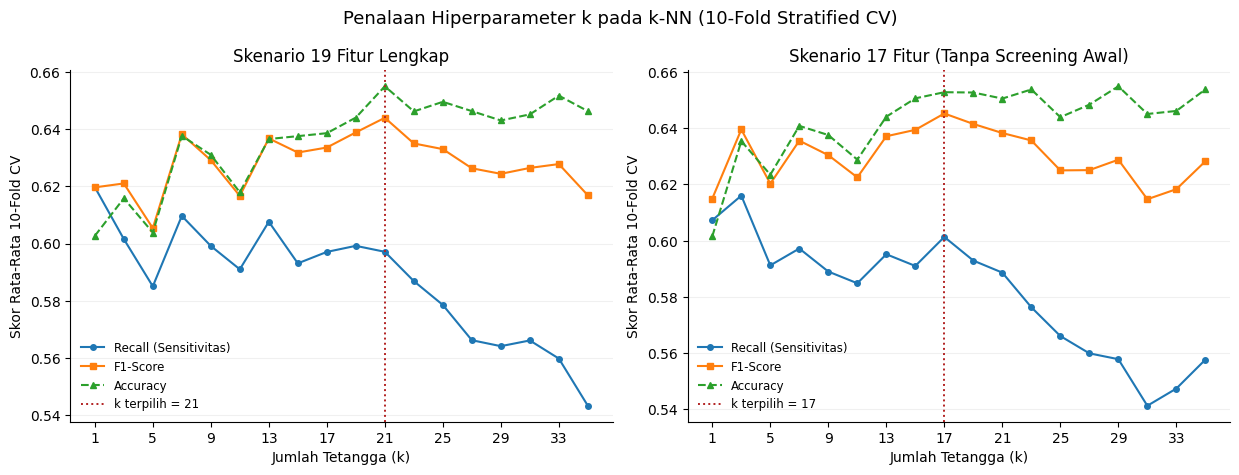

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

for ax, (df_sub, title_sub, k_best) in zip(
    axes,
    [
        (cv_19, "Skenario 19 Fitur Lengkap", k_opt_19),
        (cv_17, "Skenario 17 Fitur (Tanpa Screening Awal)", k_opt_17),
    ],
):
    ax.plot(df_sub["k"], df_sub["cv_recall"], marker="o", markersize=4, label="Recall (Sensitivitas)")
    ax.plot(df_sub["k"], df_sub["cv_f1"], marker="s", markersize=4, label="F1-Score")
    ax.plot(df_sub["k"], df_sub["cv_accuracy"], marker="^", markersize=4, linestyle="--", label="Accuracy")
    ax.axvline(k_best, color="#b22222", linestyle=":", linewidth=1.4, label=f"k terpilih = {k_best}")
    ax.set(title=title_sub, xlabel="Jumlah Tetangga (k)", ylabel="Skor Rata-Rata 10-Fold CV")
    ax.set_xticks(k_candidates[::2])
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.18)
    ax.legend(frameon=False, fontsize=8.5)

fig.suptitle("Penalaan Hiperparameter k pada k-NN (10-Fold Stratified CV)", fontsize=13)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_kurva_cv_knn.png", dpi=220, bbox_inches="tight")
plt.show()

In [13]:
def evaluasi_model_uji(X_tr, y_tr, X_te, y_te, k_best, nama_skenario):
    model = KNeighborsClassifier(n_neighbors=k_best, metric="euclidean", weights="uniform")
    model.fit(X_tr, y_tr)

    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]

    cm = confusion_matrix(y_te, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    metrik = {
        "Skenario": nama_skenario,
        "k_optimal": k_best,
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred),
        "Recall (Sensitivitas)": recall_score(y_te, y_pred),
        "F1-Score": f1_score(y_te, y_pred),
        "ROC-AUC": roc_auc_score(y_te, y_prob),
        "True Positive (TP)": int(tp),
        "True Negative (TN)": int(tn),
        "False Positive (FP)": int(fp),
        "False Negative (FN)": int(fn),
        "False Negative Rate (FNR)": fn / (fn + tp),
    }
    return metrik, cm, y_prob


metrik_19, cm_19, prob_19 = evaluasi_model_uji(
    X_train_19, y_train_19, X_test_19, y_test_19, k_opt_19, "k-NN (19 Fitur Lengkap)"
)
metrik_17, cm_17, prob_17 = evaluasi_model_uji(
    X_train_17, y_train_17, X_test_17, y_test_17, k_opt_17, "k-NN (17 Fitur)"
)

df_evaluasi = pd.DataFrame([metrik_19, metrik_17])
display(df_evaluasi.round(4))
df_evaluasi.to_csv(OUTPUT_DIR / "evaluasi_uji_knn.csv", index=False)

,Skenario,k_optimal,Accuracy,Precision,Recall (Sensitivitas),F1-Score,ROC-AUC,True Positive (TP),True Negative (TN),False Positive (FP),False Negative (FN),False Negative Rate (FNR)
0,k-NN (19 Fitur Lengkap),21,0.6304,0.6832,0.5656,0.6188,0.7050,69,76,32,53,0.4344
1,k-NN (17 Fitur),17,0.5826,0.6354,0.5000,0.5596,0.6781,61,73,35,61,0.5000


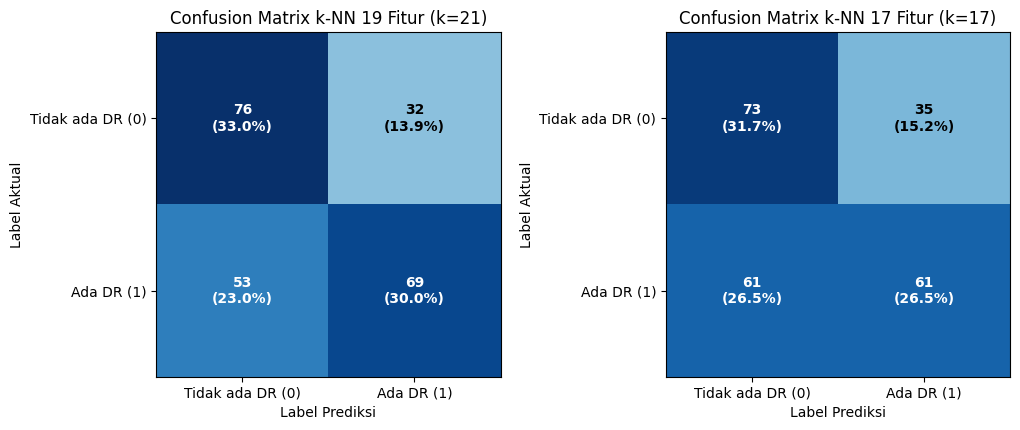

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
kelas_labels = ["Tidak ada DR (0)", "Ada DR (1)"]

for ax, (cm, title_cm) in zip(
    axes,
    [
        (cm_19, f"Confusion Matrix k-NN 19 Fitur (k={k_opt_19})"),
        (cm_17, f"Confusion Matrix k-NN 17 Fitur (k={k_opt_17})"),
    ],
):
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=max(cm_19.max(), cm_17.max()))
    ax.set_xticks([0, 1], labels=kelas_labels)
    ax.set_yticks([0, 1], labels=kelas_labels)
    ax.set(xlabel="Label Prediksi", ylabel="Label Aktual", title=title_cm)

    total_uji = cm.sum()
    for i in range(2):
        for j in range(2):
            val = cm[i, j]
            pct = 100.0 * val / total_uji
            warna_teks = "white" if val > (cm.max() * 0.55) else "black"
            ax.text(
                j, i, f"{val}\n({pct:.1f}%)",
                ha="center", va="center", color=warna_teks, fontsize=10, fontweight="bold"
            )

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_confusion_matrix_knn.png", dpi=220, bbox_inches="tight")
plt.show()

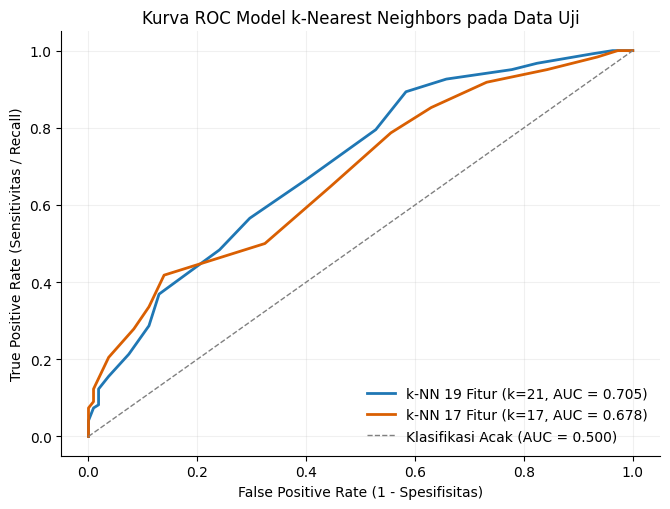

In [15]:
fig, ax = plt.subplots(figsize=(6.8, 5.2))

for prob, label_roc, color_line in [
    (prob_19, f"k-NN 19 Fitur (k={k_opt_19}, AUC = {metrik_19['ROC-AUC']:.3f})", "#1f77b4"),
    (prob_17, f"k-NN 17 Fitur (k={k_opt_17}, AUC = {metrik_17['ROC-AUC']:.3f})", "#d95f02"),
]:
    fpr, tpr, _ = roc_curve(y_test_19, prob)
    ax.plot(fpr, tpr, linewidth=2, color=color_line, label=label_roc)

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1, label="Klasifikasi Acak (AUC = 0.500)")
ax.set(
    title="Kurva ROC Model k-Nearest Neighbors pada Data Uji",
    xlabel="False Positive Rate (1 - Spesifisitas)",
    ylabel="True Positive Rate (Sensitivitas / Recall)",
)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.18)
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_kurva_roc_knn.png", dpi=220, bbox_inches="tight")
plt.show()

In [16]:
ringkasan_teks = "\n".join(
    [
        "RINGKASAN PEMODELAN & EVALUASI k-NEAREST NEIGHBORS (k-NN)",
        "Diabetic Retinopathy Debrecen | Kelompok 7",
        f"Data Latih: {len(X_train_19)} observasi | Data Uji: {len(X_test_19)} observasi",
        f"19 Fitur -> k optimal = {k_opt_19} | Accuracy = {metrik_19['Accuracy']:.4f} | "
        f"Precision = {metrik_19['Precision']:.4f} | Recall = {metrik_19['Recall (Sensitivitas)']:.4f} | "
        f"F1 = {metrik_19['F1-Score']:.4f} | ROC-AUC = {metrik_19['ROC-AUC']:.4f} | "
        f"TP = {metrik_19['True Positive (TP)']} | TN = {metrik_19['True Negative (TN)']} | "
        f"FP = {metrik_19['False Positive (FP)']} | FN = {metrik_19['False Negative (FN)']}",
        f"17 Fitur -> k optimal = {k_opt_17} | Accuracy = {metrik_17['Accuracy']:.4f} | "
        f"Precision = {metrik_17['Precision']:.4f} | Recall = {metrik_17['Recall (Sensitivitas)']:.4f} | "
        f"F1 = {metrik_17['F1-Score']:.4f} | ROC-AUC = {metrik_17['ROC-AUC']:.4f} | "
        f"TP = {metrik_17['True Positive (TP)']} | TN = {metrik_17['True Negative (TN)']} | "
        f"FP = {metrik_17['False Positive (FP)']} | FN = {metrik_17['False Negative (FN)']}",
    ]
)

print(ringkasan_teks)
(OUTPUT_DIR / "ringkasan_knn.txt").write_text(ringkasan_teks, encoding="utf-8")

arsip = Path("Hasil_KNN_Diabetic_Retinopathy_Kelompok_7.zip")
with ZipFile(arsip, "w", compression=ZIP_DEFLATED) as zf:
    for berkas in sorted(OUTPUT_DIR.iterdir()):
        if berkas.is_file():
            zf.write(berkas, arcname=berkas.name)

print(f"\nArsip hasil siap diunduh: {arsip.name}")

RINGKASAN PEMODELAN & EVALUASI k-NEAREST NEIGHBORS (k-NN)
Diabetic Retinopathy Debrecen | Kelompok 7
Data Latih: 916 observasi | Data Uji: 230 observasi
19 Fitur -> k optimal = 21 | Accuracy = 0.6304 | Precision = 0.6832 | Recall = 0.5656 | F1 = 0.6188 | ROC-AUC = 0.7050 | TP = 69 | TN = 76 | FP = 32 | FN = 53
17 Fitur -> k optimal = 17 | Accuracy = 0.5826 | Precision = 0.6354 | Recall = 0.5000 | F1 = 0.5596 | ROC-AUC = 0.6781 | TP = 61 | TN = 73 | FP = 35 | FN = 61

Arsip hasil siap diunduh: Hasil_KNN_Diabetic_Retinopathy_Kelompok_7.zip
